,victimas,pct_acumulado
delito,,
VIOLENCIA FAMILIAR,101877,16.2
FRAUDE,58346,25.5
AMENAZAS,52913,33.9
ROBO DE OBJETOS,30667,38.7
ROBO DE ACCESORIOS DE AUTO,25671,42.8
ROBO A TRANSEUNTE EN VIA PUBLICA CON VIOLENCIA,19661,45.9
ROBO DE OBJETOS DEL INTERIOR DE UN VEHICULO,17708,48.7
USURPACIÓN DE IDENTIDAD,16345,51.3
ABUSO SEXUAL,12046,53.3


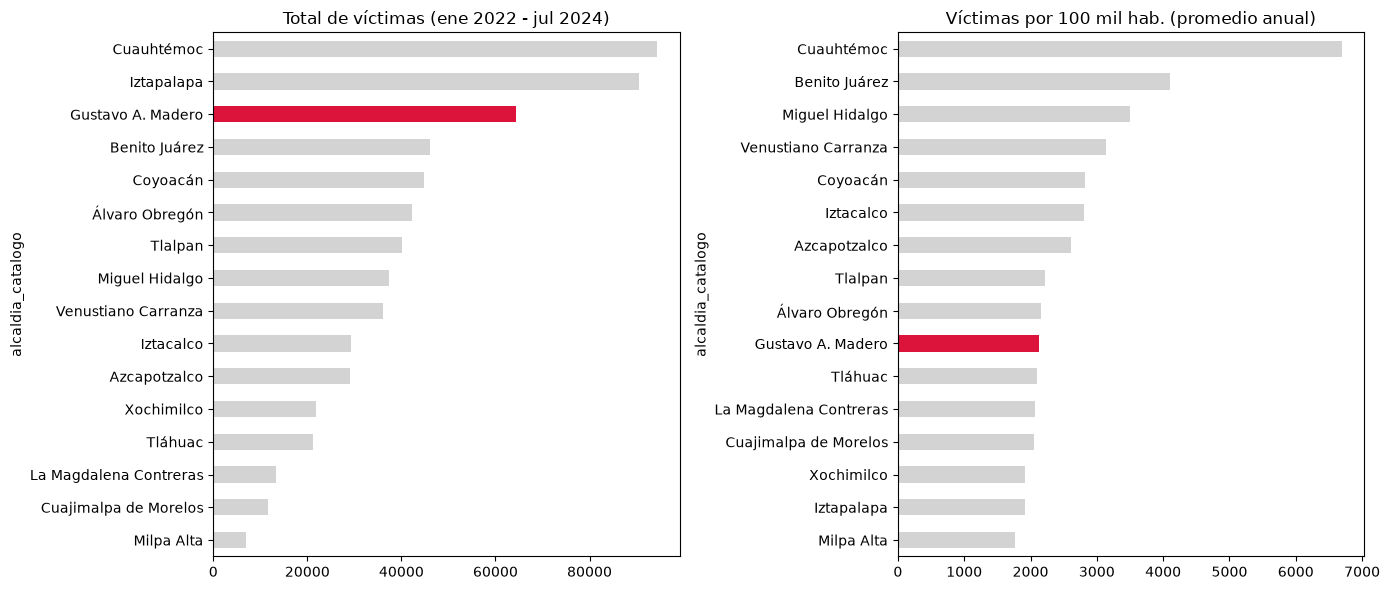

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

cdmx = pd.read_parquet("victimas_cdmx_limpio.parquet")
cdmx.shape


poblacion = {
    "Iztapalapa": 1835486, "Gustavo A. Madero": 1173351, "Álvaro Obregón": 759137,
    "Tlalpan": 699928, "Coyoacán": 614447, "Cuauhtémoc": 545884,
    "Venustiano Carranza": 443704, "Xochimilco": 442178, "Benito Juárez": 434153,
    "Azcapotzalco": 432205, "Miguel Hidalgo": 414470, "Iztacalco": 404695,
    "Tláhuac": 392313, "La Magdalena Contreras": 247622,
    "Cuajimalpa de Morelos": 217686, "Milpa Alta": 152685,
}
sum(poblacion.values())   # debe dar 9,209,944: la población total de la CDMX en 2020

MESES = 31  # enero 2022 a julio 2024
t = cdmx.groupby("alcaldia_catalogo").size().rename("victimas").to_frame()
t["poblacion"] = t.index.map(poblacion)
t["pct_ciudad"] = t["victimas"] / t["victimas"].sum() * 100
t["tasa_anual_100k"] = t["victimas"] / (MESES / 12) / t["poblacion"] * 100_000
t["rank_total"] = t["victimas"].rank(ascending=False).astype(int)
t["rank_tasa"] = t["tasa_anual_100k"].rank(ascending=False).astype(int)
t = t.sort_values("victimas", ascending=False).round(1)
t


fig, ax = plt.subplots(1, 2, figsize=(14, 6))
colores = ["crimson" if a == "Gustavo A. Madero" else "lightgray" for a in t.index]
t["victimas"].plot.barh(ax=ax[0], color=colores, title="Total de víctimas (ene 2022 - jul 2024)")
orden = t.sort_values("tasa_anual_100k")
orden["tasa_anual_100k"].plot.barh(ax=ax[1],
    color=["crimson" if a == "Gustavo A. Madero" else "lightgray" for a in orden.index],
    title="Víctimas por 100 mil hab. (promedio anual)")
ax[0].invert_yaxis()
plt.tight_layout()

top = cdmx["delito"].value_counts()
pareto = (top.cumsum() / top.sum() * 100).round(1)
pd.DataFrame({"victimas": top, "pct_acumulado": pareto}).head(20)
